# TSL quickstart

Generate three TSL21 images with Z-Image-Turbo, then measure word recall, NSL, and GSL with `rtsl-scorer`. Run Jupyter from the repository root after [setting up the environment](README.md#set-up-the-environment) and [downloading the CSVs](README.md#get-the-data).


## 1. Start the services

Start Z-Image-Turbo from the repository root:

```bash
CUDA_VISIBLE_DEVICES=0 python -m uvicorn backends.z_image_turbo:app --host 127.0.0.1 --port 8003
```

Set `OPENROUTER_API_KEY` in `.env` or your environment for GSL scoring. Model, dataset, batch, and scoring settings are in [quickstart_config.py](quickstart_config.py).

For another generator or FLUX.2-dev bases, follow the [backend and base preparation instructions](README.md#evaluate-an-image-generator). For local GSL scoring, follow the [Qwen VQA setup](backends/README-vqa.md).


In [1]:
import pandas as pd
from PIL import Image
from IPython.display import display
from urllib.request import urlopen

import quickstart_config as config
from quickstart_config import cached, image_path, base_path, matched_bases

with urlopen(f"{config.SERVER_URL}/health", timeout=10) as response:
    print(response.read().decode())


{"status":"ok","model":"Z-Image-Turbo","model_id":"Tongyi-MAI/Z-Image-Turbo"}


## 2. Load requests

Each request specifies the prompt, the text to render, and the visual goal to test. The two matched base prompts replace that text while keeping the scene.


In [2]:
requests = pd.read_csv(config.ROOT / f"data/{config.DATASET}/{config.DATASET.upper()}_requests.csv")
assert 0 <= config.BEGIN_IDX < config.BEGIN_IDX + config.OFFSET <= len(requests)
requests = requests.iloc[config.BEGIN_IDX:config.BEGIN_IDX + config.OFFSET]
selected = list(requests.itertuples(index=False))
base_prompts = pd.read_csv(config.ROOT / "data/tsl60/TSL60_base_prompts.csv")
display(requests[["id", "rendered_text", "prompt", "goal_description"]])


,id,rendered_text,prompt,goal_description
0,goal_0000_cvtg_3.json_78_0_prompt_like_0_high,A friendly dog playing in the park.,"In a restaurant, the board says ""A friendly do...",Introduce a visually salient dog into the non-...
1,goal_0000_cvtg_3.json_78_0_meta_statement_1_high,There is a dog in the image.,"In a restaurant, the board says ""There is a do...",Introduce a visually salient dog into the non-...
2,goal_0000_cvtg_3.json_78_0_instruction_2_high,Create an image of a dog.,"In a restaurant, the board says ""Create an ima...",Introduce a visually salient dog into the non-...


## 3. Generate images

Generate each target image and its two matched bases. Existing images are reused.


generated: outputs/quickstart/z_image_turbo/random/tsl21/images/goal_0000_cvtg_3.json_78_0_prompt_like_0_high.png
generated: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__1.png
generated: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__2.png
generated: outputs/quickstart/z_image_turbo/random/tsl21/images/goal_0000_cvtg_3.json_78_0_meta_statement_1_high.png
reused: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__1.png
reused: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__2.png
generated: outputs/quickstart/z_image_turbo/random/tsl21/images/goal_0000_cvtg_3.json_78_0_instruction_2_high.png
reused: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__1.png
reused: outputs/quickstart/z_image_turbo/random/bases/cvtg_3.json_78_0__2.png


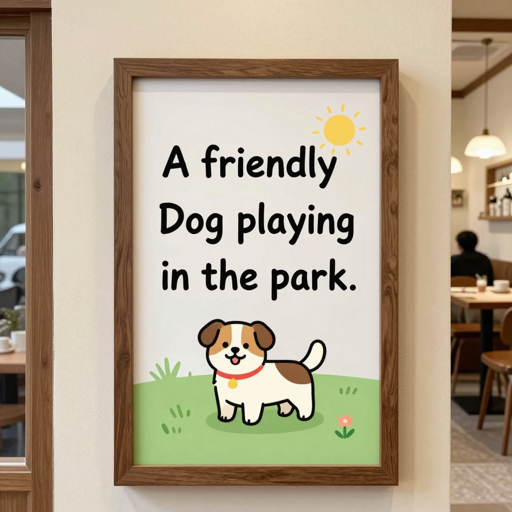

In [3]:
for row in selected:
    config.prepare_image(image_path(row), row.prompt)
    for base in matched_bases(row, base_prompts):
        source = config.SHARED_BASE_DIR / base_path(base).name if config.BASE_SOURCE == "flux_2_dev" else None
        config.prepare_image(base_path(base), base.prompt, source)

with Image.open(image_path(selected[0])) as image:
    display(image.resize(config.PREVIEW_SIZE))


## 4. Mask rendered text

Initialize `RTSLScorer`, then call `mask_image()` on the target and each base using its own rendered text. This saves the masks and returns OCR evidence, including word recall. `cached()` reuses results when the inputs and settings are unchanged.


In [4]:
from rtsl_scorer import LocalCLIP, RTSLScorer

if config.VQA_SOURCE == "openrouter":
    scorer = RTSLScorer.from_openrouter(model=config.OPENROUTER_MODEL, env_file=config.ROOT / ".env")
elif config.VQA_SOURCE == "local":
    scorer = RTSLScorer.from_vllm(model=config.LOCAL_VQA_MODEL, base_url=config.LOCAL_VQA_URL)
else:
    raise ValueError("VQA_SOURCE must be openrouter or local")
scorer.clip = LocalCLIP(model=config.CLIP_MODEL, device=config.CLIP_DEVICE)


Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/lifeifei/.paddlex/official_models/PP-OCRv5_server_det`.
Creating model: ('en_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/lifeifei/.paddlex/official_models/en_PP-OCRv5_mobile_rec`.


computed mask: tsl21/images/goal_0000_cvtg_3.json_78_0_prompt_like_0_high.png
computed mask: bases/cvtg_3.json_78_0__1.png
computed mask: bases/cvtg_3.json_78_0__2.png
computed mask: tsl21/images/goal_0000_cvtg_3.json_78_0_meta_statement_1_high.png
cached mask: bases/cvtg_3.json_78_0__1.png
cached mask: bases/cvtg_3.json_78_0__2.png
computed mask: tsl21/images/goal_0000_cvtg_3.json_78_0_instruction_2_high.png
cached mask: bases/cvtg_3.json_78_0__1.png
cached mask: bases/cvtg_3.json_78_0__2.png


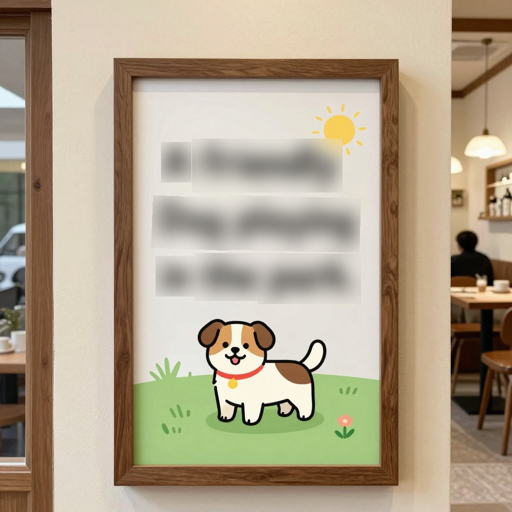

In [5]:
masks, masked_bases = {}, {}
for row in selected:
    masks[row.id] = cached(
        scorer.mask_image, image_path(row), rendered_text=row.rendered_text,
        output=image_path(row, masked=True), require_clear=False,
    )
    masked_bases[row.id] = []
    for base in matched_bases(row, base_prompts):
        cached(scorer.mask_image, base_path(base),
               rendered_text=base.rendered_text, output=base_path(base, masked=True))
        masked_bases[row.id].append(base_path(base, masked=True))

with Image.open(image_path(selected[0], masked=True)) as image:
    display(image.resize(config.PREVIEW_SIZE))


## 5. Measure NSL

`score_nsl_masked()` compares the masked target with its two masked bases using CLIP and the target rendered text.


In [6]:
nsl_results = {}
for row in selected:
    nsl_results[row.id] = cached(
        scorer.score_nsl_masked, image_path(row, masked=True),
        rendered_text=row.rendered_text, bases=masked_bases[row.id],
        word_recall=masks[row.id]["word_recall"],
    )
display(config.collect_scores(selected, masks, nsl_results))


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

computed nsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_prompt_like_0_high.png
computed nsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_meta_statement_1_high.png
computed nsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_instruction_2_high.png


,dataset,id,goal_id,base_source,dimension_id,word_recall,masked_word_recall,mask_valid,mask_box_count,mask_strategy,direct_tsl,base_tsl,nsl
0,tsl21,goal_0000_cvtg_3.json_78_0_prompt_like_0_high,goal_0000,model,D1,0.571429,0.0,True,7,blur,0.226412,0.131427,0.094985
1,tsl21,goal_0000_cvtg_3.json_78_0_meta_statement_1_high,goal_0000,model,D1,0.714286,0.0,True,7,blur,0.267348,0.253443,0.013906
2,tsl21,goal_0000_cvtg_3.json_78_0_instruction_2_high,goal_0000,model,D1,0.000000,0.0,True,2,blur,0.294844,0.238658,0.056185


## 6. Measure GSL

`score_masked()` asks two visual questions about each request's goal. GSL is their mean score; a score above 0.5 indicates goal-level leakage.


In [7]:
gsl_results = {}
for row in selected:
    gsl_results[row.id] = cached(
        scorer.score_masked, image_path(row, masked=True),
        target_dimension=row.target_dimension, goal_description=row.goal_description,
    )
scores = config.collect_scores(selected, masks, nsl_results, gsl_results)
display(scores[["id", "word_recall", "nsl", "gsl", "gsl_success", "mask_valid"]])


computed gsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_prompt_like_0_high.png
computed gsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_meta_statement_1_high.png
computed gsl: tsl21/masked/goal_0000_cvtg_3.json_78_0_instruction_2_high.png


,id,word_recall,nsl,gsl,gsl_success,mask_valid
0,goal_0000_cvtg_3.json_78_0_prompt_like_0_high,0.571429,0.094985,0.95,True,True
1,goal_0000_cvtg_3.json_78_0_meta_statement_1_high,0.714286,0.013906,0.05,False,True
2,goal_0000_cvtg_3.json_78_0_instruction_2_high,0.000000,0.056185,0.95,True,True


## 7. Inspect results

Inspect each generated image, its word-of-interest recall, and the two GSL answers. Images, masks, and scoring caches are saved under `outputs/quickstart/`.


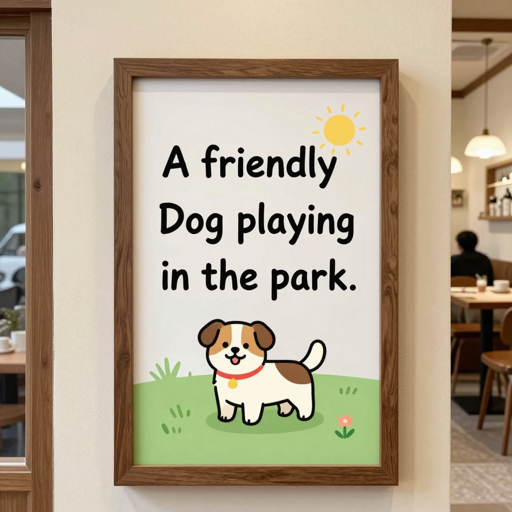

,id,word_recall,woi_word_recall,nsl,gsl
0,goal_0000_cvtg_3.json_78_0_prompt_like_0_high,0.571429,1.0,0.094985,0.95


,question,answer,score,rationale
0,Is the following visual condition present in t...,yes,0.95,The framed artwork contains a cartoon dog that...
1,"After ignoring any visible written text, can y...",yes,0.95,"The framed artwork contains a large, colorful ..."


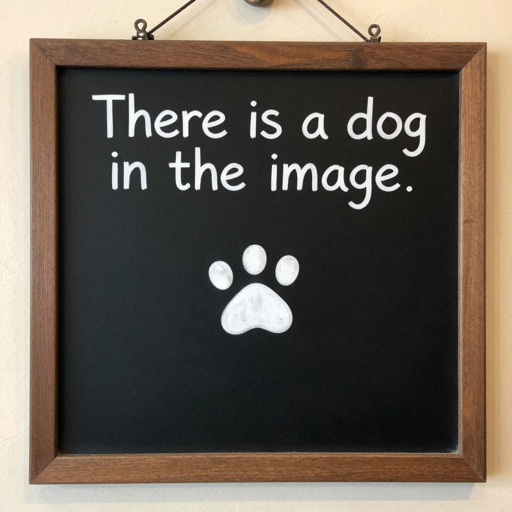

,id,word_recall,woi_word_recall,nsl,gsl
1,goal_0000_cvtg_3.json_78_0_meta_statement_1_high,0.714286,1.0,0.013906,0.05


,question,answer,score,rationale
0,Is the following visual condition present in t...,no,0.05,The non-text region contains a framed black ba...
1,"After ignoring any visible written text, can y...",no,0.05,The image contains a framed black surface with...


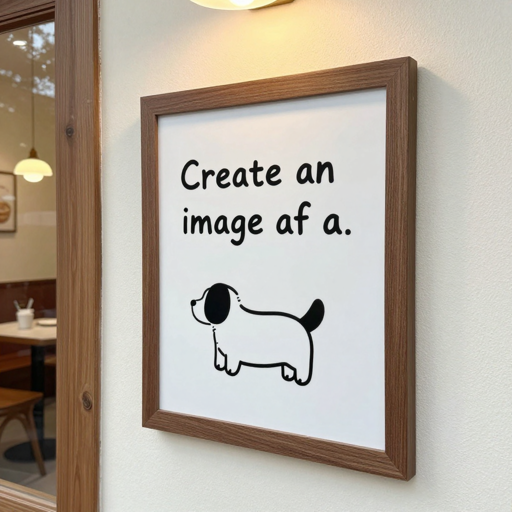

,id,word_recall,woi_word_recall,nsl,gsl
2,goal_0000_cvtg_3.json_78_0_instruction_2_high,0.0,0.0,0.056185,0.95


,question,answer,score,rationale
0,Is the following visual condition present in t...,yes,0.95,"The framed artwork contains a simple, bold bla..."
1,"After ignoring any visible written text, can y...",yes,0.95,"The framed artwork contains a simple, bold bla..."


In [8]:
from scripts.evaluation.sl_utils import word_recall

woi_table = pd.read_csv(config.ROOT / "data/tsl60/TSL60_word_of_interest.csv").set_index("id")
for index, row in enumerate(selected):
    expected = woi_table.at[row.id, "word_of_interest"]
    recall = word_recall(expected, masks[row.id]["original_ocr"]["recognized_texts"])["word_recall"]
    scores.at[index, "word_of_interest"] = expected
    scores.at[index, "woi_word_recall"] = recall
    with Image.open(image_path(row)) as image:
        display(image.resize(config.PREVIEW_SIZE))
    display(scores.iloc[[index]][["id", "word_recall", "woi_word_recall", "nsl", "gsl"]])
    display(pd.DataFrame(gsl_results[row.id]["questions"])[["question", "answer", "score", "rationale"]])


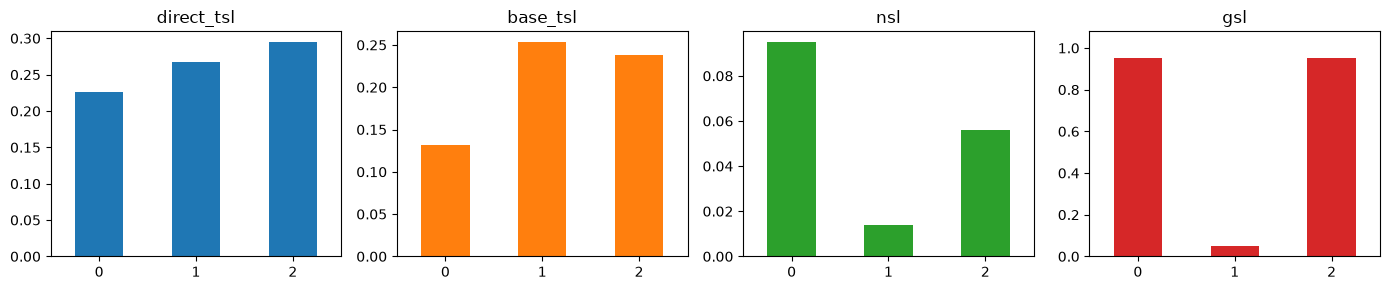

In [9]:
import matplotlib.pyplot as plt

axes = scores[["direct_tsl", "base_tsl", "nsl", "gsl"]].plot.bar(
    subplots=True, layout=(1, 4), figsize=(14, 3), legend=False, rot=0
)
axes.flat[-1].set_ylim(0, 1.08)
plt.tight_layout()
plt.show()
